# Lecture 6 Activity – Who were the members in the middle?

QSS 20 · Modern Statistical Computing · Fall 2026

## The question

In lecture we counted **overlapping Democrats**: Democrats whose `dwnom1` score
is higher than the lowest Republican score in the same Congress. There were 134
in the 80th Congress (1947–49) and none from the 108th (2003–05) on.

The scatter plot of the 80th Congress also showed the Democrats in two clouds.
Lecture 4's activity found that Southern Democrats sat well to the right of
other Democrats.

> **Were the overlapping Democrats mostly Southern, and did Southern Democrats
> stop standing apart from the rest of their party?**

### Reminders

- One row is **one member of the House in one Congress**.
- `dwnom1`: negative liberal, positive conservative. `dwnom2` is the second
  score; in these decades it mostly separated members by region, including on
  civil rights.
- Before you read a chart, say what one mark stands for.
- In the starter cells, replace each `...` with code.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', 8)

# Figure quality, as in lecture: sharp on screen, 300 dpi in saved files.
%config InlineBackend.figure_format = 'retina'
plt.rcParams['savefig.dpi'] = 300

congress = pd.read_csv('../data/raw/congress.csv')
house = congress.loc[congress['district'] != 0]
two = house.loc[house['party'] != 'Other']

# The eleven states of the former Confederacy, spelled as in the file.
south = ['ALABAMA', 'ARKANSA', 'FLORIDA', 'GEORGIA', 'LOUISIA', 'MISSISS',
         'NORTH C', 'SOUTH C', 'TENNESS', 'TEXAS', 'VIRGINI']

two = two.assign(region=two['state'].isin(south).map({True: 'South', False: 'Non-South'}))
colors = {'Democrat': '#1f4e9c', 'Republican': '#c8102e'}

# Check: 105 Southern Democrats and 2 Southern Republicans in the 80th Congress.
two.loc[two['congress'] == 80].groupby(['region', 'party']).size()

region     party     
Non-South  Democrat       88
           Republican    248
South      Democrat      105
           Republican      2
dtype: int64

## Task 1 · Where were the overlapping Democrats from?

Count the overlapping Democrats in every Congress, **separately** for the South
and the rest of the country. Then draw both counts as two lines on one Axes,
with labeled axes.

1. In the 80th Congress, how many of the 134 overlapping Democrats were
   Southern?
2. A few Democrats still overlapped in the 105th to 107th Congresses
   (1997–2003). Print their Congress, state, name, and score. Which regions
   were they from?

In [2]:
# The lowest Republican score in each Congress: one number per Congress.
rep_min = two.loc[two['party'] == 'Republican'].groupby('congress')['dwnom1'].min()

dems = two.loc[two['party'] == 'Democrat']
dems = dems.assign(rep_min=dems['congress'].map(rep_min))
dems = dems.assign(over=dems['dwnom1'] > dems['rep_min'])

over_by_region = dems.pivot_table(index='congress', columns='region',
                                  values='over', aggfunc='sum')
over_by_region.loc[[80, 88, 96, 104]]

region,Non-South,South
congress,,
80,33,101
88,7,62
96,15,32
104,0,3


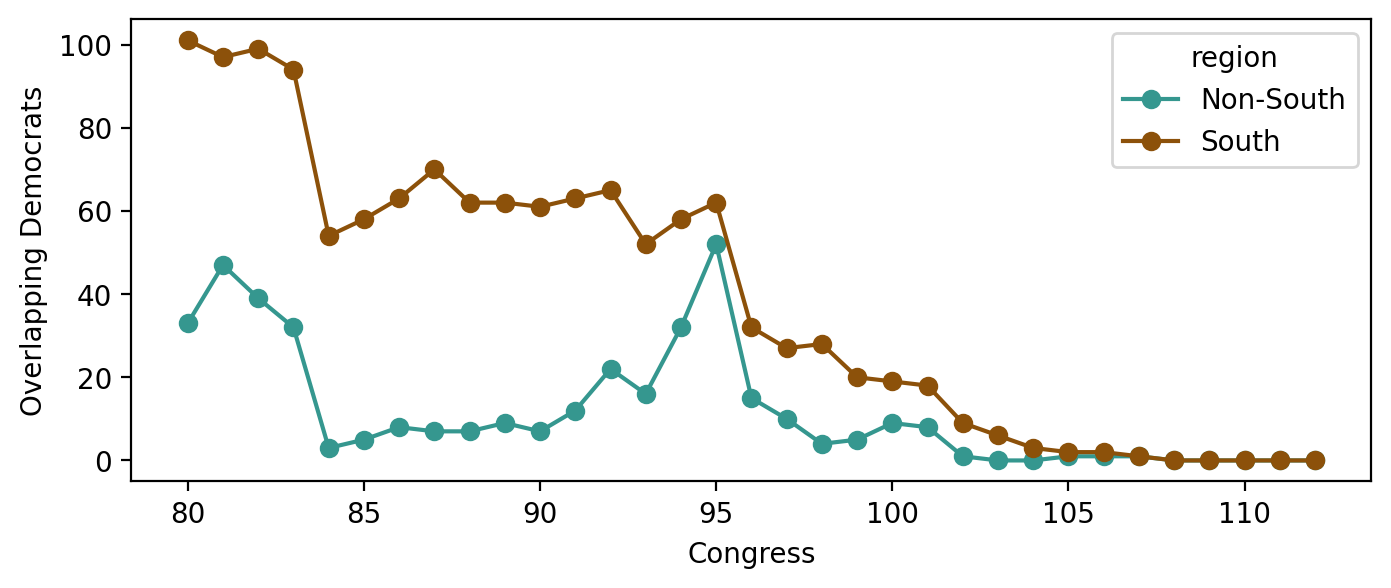

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
over_by_region.plot(ax=ax, marker='o', color={'South': '#8c510a', 'Non-South': '#35978f'})
ax.set(xlabel='Congress', ylabel='Overlapping Democrats');

In [4]:
dems.loc[dems['over'] & dems['congress'].between(105, 107),
         ['congress', 'state', 'name', 'dwnom1']]

,congress,state,name,dwnom1
11334,105,OHIO,TRAFICANT,0.047
11391,105,TEXAS,HALL RALPH,0.091
11426,105,VIRGINI,GOODE,0.127
11774,106,OHIO,TRAFICANT,0.106
11830,106,TEXAS,HALL RALPH,0.088
11865,106,VIRGINI,GOODE,0.127
12214,107,OHIO,TRAFICANT,0.165
12272,107,TEXAS,HALL RALPH,0.085


In the 80th Congress, **101 of the 134** overlapping Democrats were Southern. In
the 88th (1963–65) it was 62 of 69, and in the 96th, 32 of 47.

The non-Southern count fell to 0 in the 103rd Congress (1993–95). The last
overlapping Democrats, in the 105th to 107th, were Traficant of Ohio, Hall of
Texas, and Goode of Virginia. Two of the three were Southern. From the 108th
on, there were none.

The Democrats who overlapped the Republicans were mostly Southern, from the
first Congress in the file to the last one with any overlap.

## Task 2 · Did Southern Democrats stop standing apart?

Draw two panels side by side, on shared axes: the `dwnom1` scores of
**Democrats** in the 80th Congress and in the 112th, with one colour per
region. Scale each region to area 1, since the regions differ in size.

Then print the mean `dwnom1` by region in both Congresses. In which Congress do
Southern Democrats stand apart?

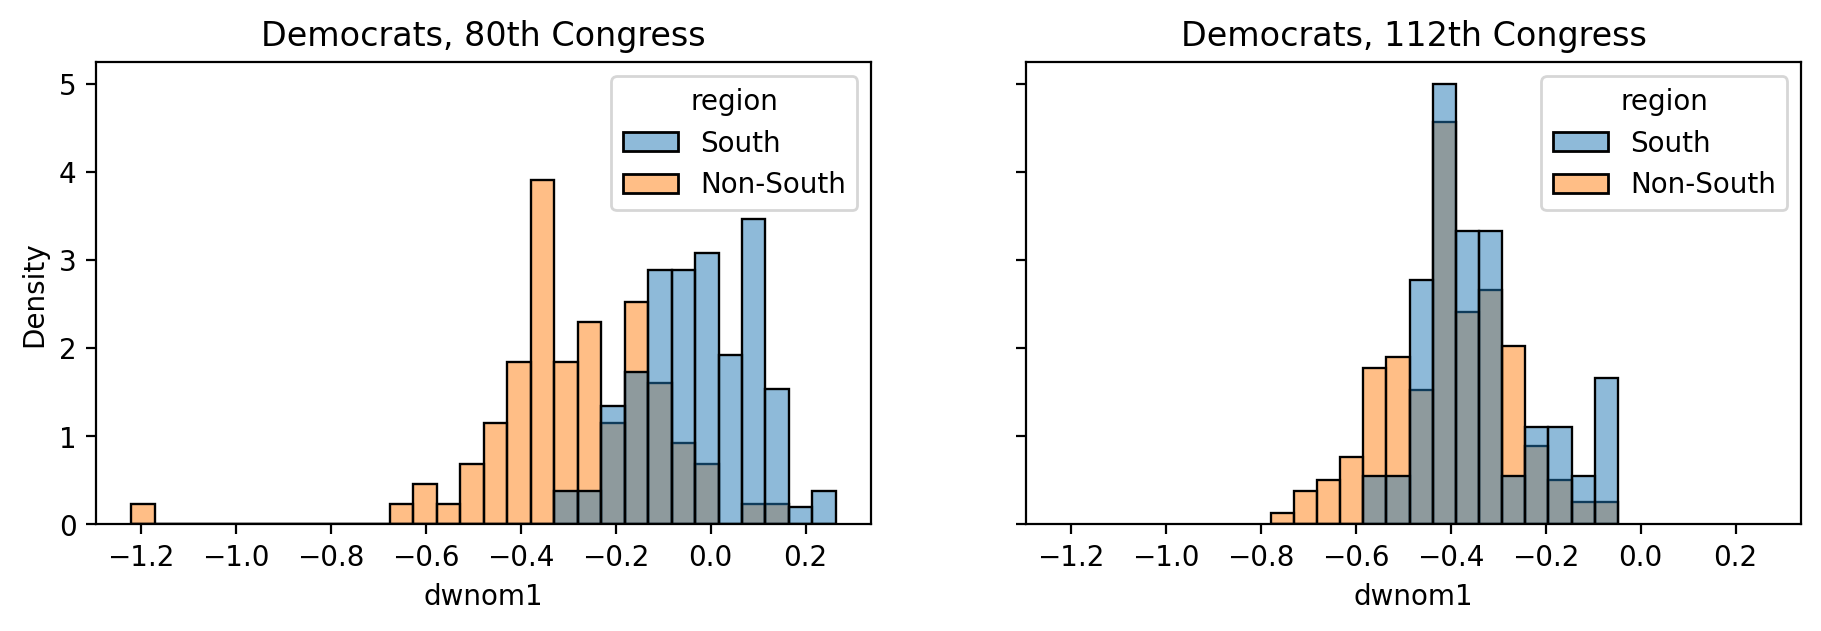

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharex=True, sharey=True)

for ax, c in zip(axes, [80, 112]):
    sns.histplot(data=dems.loc[dems['congress'] == c], x='dwnom1', hue='region',
                 binwidth=0.05, stat='density', common_norm=False, ax=ax)
    ax.set(title=f'Democrats, {c}th Congress')

In [6]:
(dems.loc[dems['congress'].isin([80, 112])]
     .groupby(['congress', 'region'])['dwnom1']
     .mean()
     .unstack()
     .round(3))

region,Non-South,South
congress,,
80,-0.285,-0.027
112,-0.406,-0.342


In the 80th Congress, Southern Democrats averaged **-0.027** and other Democrats
**-0.285**: the Southern histogram sits well to the right. In the 112th the two
means are **-0.342** and **-0.406**, and the histograms mostly overlap.

By 2011 the Southern Democrats in the House voted much like the rest of their
party.

## Task 3 · ❓ Which cloud is the South?

Make a column `group` that combines party and region, such as
`'Democrat, South'`. Then draw a scatter plot of `dwnom1` (x) against `dwnom2`
(y) for the 80th Congress, with one colour per group.

Which cloud do the Southern Democrats form? Then print the mean `dwnom2` of
each group in the 80th and the 112th Congress.

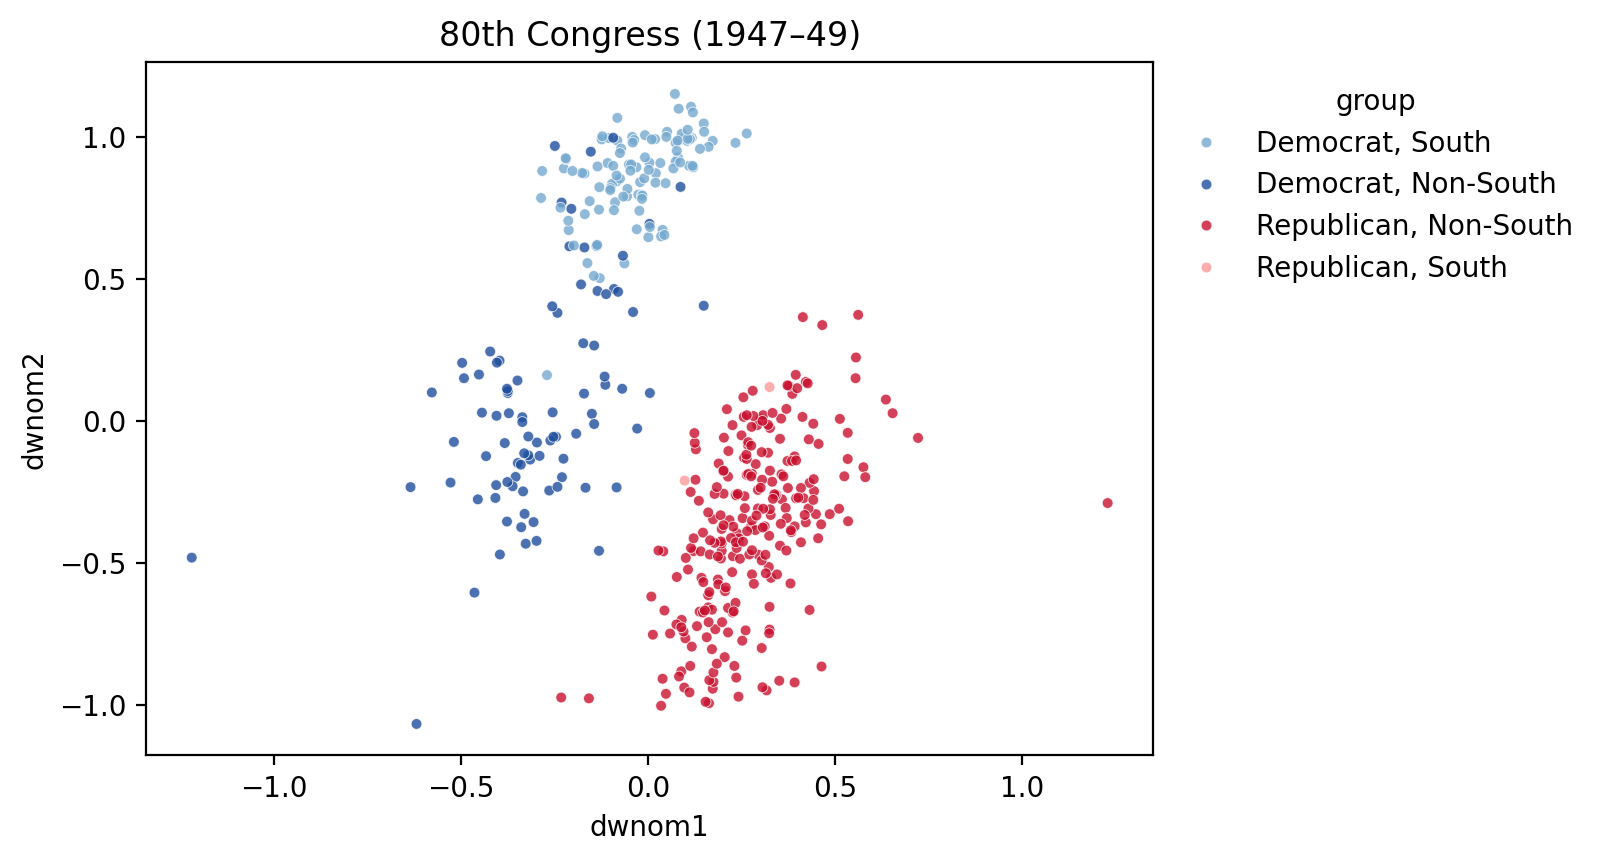

In [7]:
group_colors = {'Democrat, Non-South': '#1f4e9c', 'Democrat, South': '#74a9cf',
                'Republican, Non-South': '#c8102e', 'Republican, South': '#fb9a99'}

two = two.assign(group=two['party'] + ', ' + two['region'])
first = two.loc[two['congress'] == 80]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.scatterplot(data=first, x='dwnom1', y='dwnom2', hue='group',
                palette=group_colors, s=15, alpha=0.8, ax=ax)
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1), frameon=False)
ax.set(title='80th Congress (1947–49)');

In [8]:
(two.loc[two['congress'].isin([80, 112])]
    .groupby(['congress', 'group'])['dwnom2']
    .mean()
    .unstack(level=0)
    .round(3))

congress,80,112
group,,
"Democrat, Non-South",0.057,-0.013
"Democrat, South",0.865,0.222
"Republican, Non-South",-0.381,0.019
"Republican, South",-0.045,0.211


The Southern Democrats form the **upper cloud**: their mean `dwnom2` in the 80th
Congress was **0.865**, against **0.057** for other Democrats. On `dwnom1` alone
they sat between the other Democrats and the Republicans. On `dwnom2` they form
a cloud of their own.

By the 112th, the Southern Democratic mean had fallen to **0.222** and the
non-Southern mean was -0.013. The regional split inside the Democratic party
had mostly closed.

## If you finish early · A figure for a reader

Draw the mean `dwnom2` of each party-region group in every Congress as four
lines on one Axes. Make it a figure for a reader: a title that states the
finding, labeled axes, a source note, and no top or right border. Save it as
`dwnom2_by_group.png`.

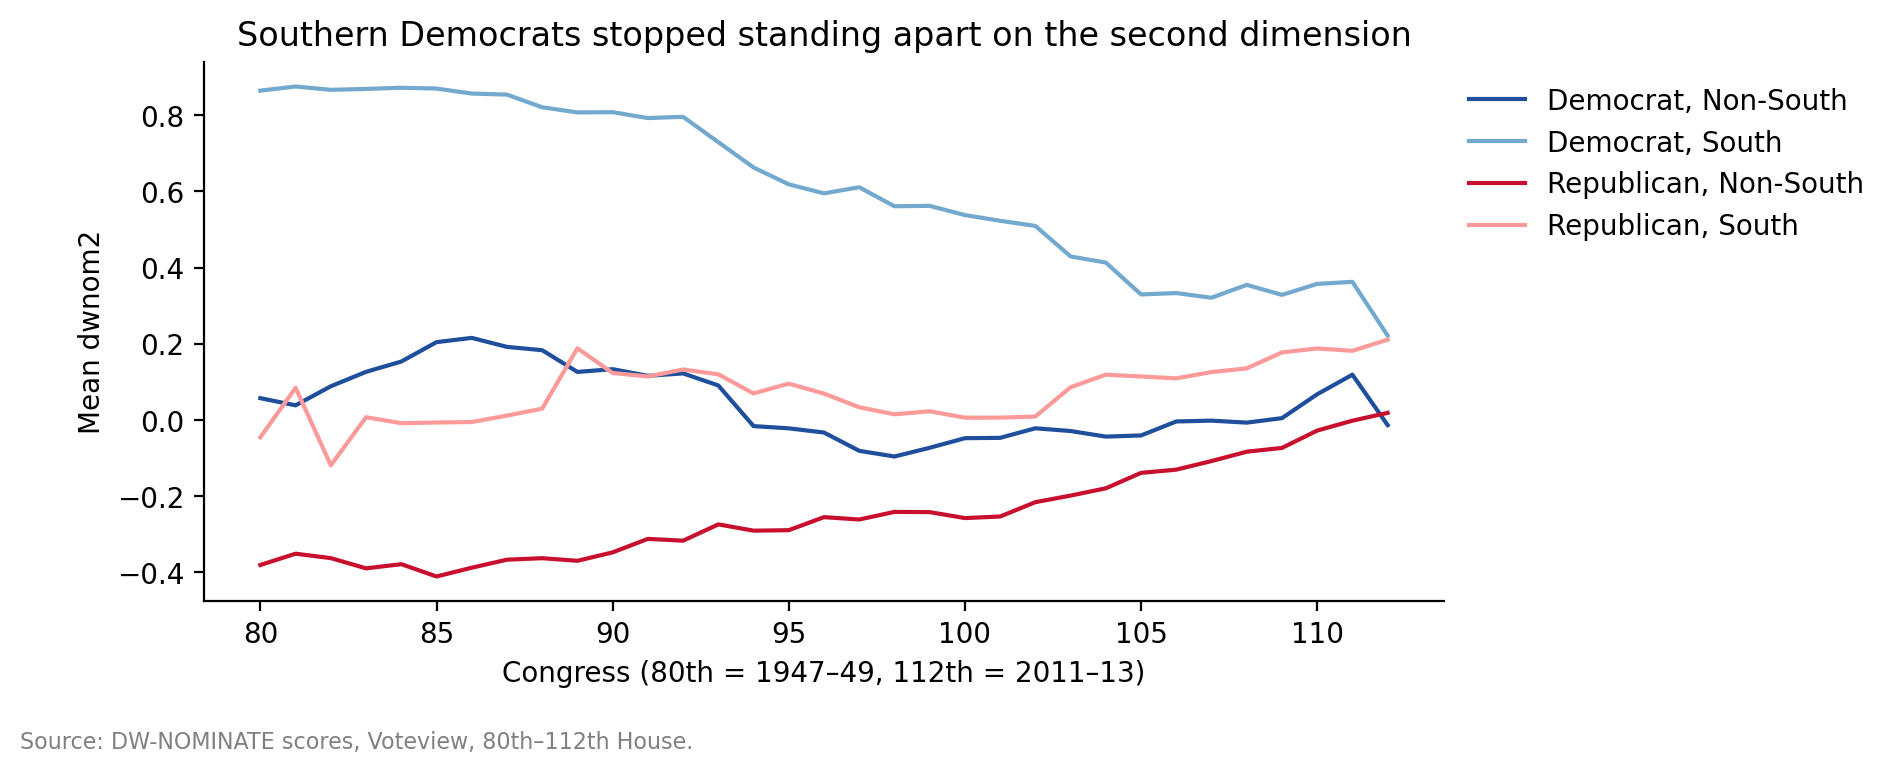

In [9]:
by_group = two.pivot_table(index='congress', columns='group', values='dwnom2',
                           aggfunc='mean')

fig, ax = plt.subplots(figsize=(8, 3.5))
by_group.plot(ax=ax, color=group_colors)
ax.set(title='Southern Democrats stopped standing apart on the second dimension',
       xlabel='Congress (80th = 1947–49, 112th = 2011–13)',
       ylabel='Mean dwnom2')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.text(0.01, -0.1, 'Source: DW-NOMINATE scores, Voteview, 80th–112th House.',
         fontsize=8, color='grey')
fig.savefig('dwnom2_by_group.png', dpi=300, bbox_inches='tight')

The Southern Democratic line starts far above the other three, at 0.865, and
falls toward them. By the 112th Congress all four group means sit between
-0.013 and 0.222.

## What to take from this

- Look at the members behind a count that depends on one extreme member (here,
  the lowest Republican). Most of the overlapping Democrats came from one
  region.
- Small multiples on shared axes show how one group changed between two
  Congresses. Colour separates the groups inside each panel.
- A second score can separate groups that look mixed on the first. Choose the
  axes from the question.